## Graphical abstract v2 — dendrogram + cell-type pies

Replaces the UMAP-based graphical abstract (`graphical_abstract.ipynb`, kept unchanged) now that the UMAP has been
removed from Figure 5. Shows the Figure 5 cluster dendrogram next to pies of the % of each cell type's cells per
cluster. Pie wedges use the dendrogram's two codes: **preferred feature** and **preferred experience level** (one as
the wedge fill, the other as an outer ring; set `PIE_FILL`). Example cluster traces come later.

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context('notebook', font_scale=1.5, rc={'lines.markeredgewidth': 1})

# Visual behavior analysis package functions
import visual_behavior.visualization.utils as utils
import visual_behavior.data_access.loading as loading

# Clustering modules
from visual_behavior.dimensionality_reduction.clustering import plotting
from visual_behavior.dimensionality_reduction.clustering import processing

%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
# Figure saving
save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'graphical_abstract_v2')
os.makedirs(save_dir, exist_ok=True)

## Data loading

In [14]:
# Curated metadata tables
metadata_tables_dir = loading.get_metadata_tables_dir()
platform_experiments = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_experiments_table.csv'), index_col=0)
platform_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_cells_table.csv'), index_col=0)

cell_types = utils.get_cell_types()
experience_levels = utils.get_experience_levels()

In [15]:
glm_results_dir = loading.get_glm_results_dir()
data_dir = loading.get_clustering_results_dir()

# Clustering results (same files as figure_5_main)
feature_matrix = pd.read_hdf(os.path.join(data_dir, 'clustering_feature_matrix.h5'), key='df')
feature_matrix = feature_matrix.rename(columns={'all-images': 'images', 'behavioral': 'behavior'})

n_clusters = 14
cluster_meta = pd.read_hdf(os.path.join(data_dir, f'cluster_metadata_{n_clusters}_clusters.h5'), key='df')

# Coding scores - normalized for clustering
results_pivoted = pd.read_hdf(os.path.join(glm_results_dir, 'across_session_normalized_platform_results_pivoted.h5'), key='df')

### Cluster preferences, dendrogram order, pie fractions

Same preferred-feature / preferred-experience definitions and dendrogram as the Figure 5 main composite (panel C).
Check the printed table against Figure 5 before using the composite.

In [16]:
# ---- per-cluster preferred feature + preferred experience, dendrogram order, pie fractions ----
# Same definitions as the Figure 5 main dendrogram (panel C of figure_5_main composite), copied so
# this notebook is self-contained. Uses only stable vars: cluster_meta, feature_matrix, results_pivoted.
#   preferred feature    = dominant feature from processing.get_coding_score_metrics_for_clusters
#   preferred experience = Familiar vs mean(Novel, Novel +) on the dominant feature:
#       novelty index = (mean(N, N+) - F) / (mean(N, N+) + F)
#       >= +EXP_SEL_MIN -> larger of Novel / Novel + ; <= -EXP_SEL_MIN -> Familiar ; else no preference
#       peak coding < EXP_SCORE_MIN -> no preference and gray feature (non-coding)
from scipy.cluster.hierarchy import linkage, dendrogram

EXP_SEL_MIN = 0.15
EXP_SCORE_MIN = 0.1

features = processing.get_features_for_clustering()           # ['all-images', 'omissions', 'task', 'behavioral']
feature_cols = plotting.get_feature_colors_with_gray()         # [gray] + one color per feature
exp_levels, exp_cols = utils.get_experience_levels(), utils.get_experience_level_colors()
FAM, NOV, NOVP = exp_levels

cm = processing.get_coding_score_metrics_for_clusters(cluster_meta, results_pivoted)
rp = (results_pivoted if 'cluster_id' in results_pivoted.columns
      else results_pivoted.merge(cluster_meta[['cluster_id']], on='cell_specimen_id'))
lvl_means = rp.groupby(['cluster_id', 'experience_level'])[features].mean()

rows = []
for c in cm.index:
    feat = cm.loc[c, 'dominant_feature']
    v = lvl_means.loc[c][feat]
    fam, nov = v[FAM], (v[NOV] + v[NOVP]) / 2
    idx = (nov - fam) / (nov + fam) if (nov + fam) > 0 else 0.0
    pref = (NOV if v[NOV] >= v[NOVP] else NOVP) if idx >= EXP_SEL_MIN else (FAM if idx <= -EXP_SEL_MIN else None)
    noncoding = max(fam, v[NOV], v[NOVP]) < EXP_SCORE_MIN
    if noncoding:
        pref = None
    rows.append(dict(cluster_id=c, dominant_feature=feat, Familiar=fam, Novel=v[NOV], **{'Novel +': v[NOVP]},
                     novelty_index=idx, preferred_experience=pref,
                     feature_color=feature_cols[0] if noncoding else feature_cols[1 + features.index(feat)],
                     exp_color=exp_cols[exp_levels.index(pref)] if pref is not None else None))
cluster_info = pd.DataFrame(rows).set_index('cluster_id').sort_index()

# dendrogram of cluster-mean coding scores (Euclidean, average linkage) -- identical to Fig 5
cent = feature_matrix.loc[cluster_meta.index].groupby(cluster_meta.cluster_id.values).mean()
dendro_Z = linkage(cent.values, method='average', metric='euclidean')
dendro_labels = list(cent.index)
# leaf order TOP -> BOTTOM as drawn with orientation='left' (scipy lists leaves bottom -> top)
leaf_order = list(dendrogram(dendro_Z, labels=dendro_labels, no_plot=True)['ivl'])[::-1]
cluster_info['dendro_rank'] = [leaf_order.index(c) for c in cluster_info.index]

# fraction of each cell type's cells in each cluster (full population, incl. cluster 1)
cell_types = utils.get_cell_types()
pie_fracs = (cluster_meta.groupby(['cell_type', 'cluster_id']).size()
             .unstack(fill_value=0).reindex(index=cell_types, columns=leaf_order, fill_value=0))
pie_fracs = pie_fracs.div(pie_fracs.sum(axis=1), axis=0)

print('leaf order (top -> bottom):', leaf_order)
print(cluster_info[['dominant_feature', FAM, NOV, NOVP, 'novelty_index', 'preferred_experience']].round(2).to_string())
print('\n% of cells per cluster, per cell type (columns in dendrogram order):')
print((100 * pie_fracs).round(1).to_string())

leaf order (top -> bottom): [9, 8, 11, 10, 1, 12, 3, 2, 5, 7, 6, 4]
           dominant_feature  Familiar  Novel  Novel +  novelty_index preferred_experience
cluster_id                                                                               
1                all-images      0.01   0.00     0.00          -0.40                 None
2                all-images      0.03   0.89     0.09           0.90                Novel
3                all-images      0.08   0.79     0.77           0.81                Novel
4                all-images      0.91   0.06     0.06          -0.87             Familiar
5                all-images      0.03   0.10     0.90           0.90              Novel +
6                all-images      0.72   0.30     0.74          -0.16             Familiar
7                all-images      0.73   0.74     0.25          -0.19             Familiar
8                 omissions      0.64   0.11     0.16          -0.65             Familiar
9                 omissions     

### Example-trace data load

Per-cell mean change- and omission-aligned responses for the trace insets (copied from `graphical_abstract.ipynb`,
same as `figure_5_main`). Slow; cached with a `globals()` guard. The composite still runs without it (traces show a placeholder).

In [17]:
# ---- data for cluster average-response traces (loaded once; slow) ----
if ('change_mdf' not in globals()) or ('omission_mdf' not in globals()):
    _dt, _interp, _osr, _incl = 'events', True, 30, 'platform_experiment_table'
    _msdf = loading.get_multi_session_df_for_conditions(
        _dt, event_type='all', conditions=['cell_specimen_id', 'is_change'],
        inclusion_criteria=_incl, interpolate=_interp, output_sampling_rate=_osr, epoch_duration_mins=None)
    _clu = cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']]
    change_mdf = _msdf[_msdf.is_change == True].merge(_clu, on='cell_specimen_id')
    image_mdf  = _msdf[_msdf.is_change == False].merge(_clu, on='cell_specimen_id')
    omission_mdf = loading.get_multi_session_df_for_conditions(
        _dt, event_type='all', conditions=['cell_specimen_id', 'omitted'],
        inclusion_criteria=_incl, interpolate=_interp, output_sampling_rate=_osr, epoch_duration_mins=None)
    omission_mdf = omission_mdf[omission_mdf.omitted == True].merge(_clu, on='cell_specimen_id')
    _thr = 99.9
    image_mdf, _    = processing.remove_outliers(image_mdf, _thr)
    change_mdf, _   = processing.remove_outliers(change_mdf, _thr)
    omission_mdf, _ = processing.remove_outliers(omission_mdf, _thr)
    # peak-amplitude outlier filtering (Method C), as the old abstract applied before plotting traces
    change_mdf = utils.drop_peak_outliers(change_mdf, data_type='events', scope='trace')
    omission_mdf = utils.drop_peak_outliers(omission_mdf, data_type='events', scope='trace')
    print('loaded change_mdf', change_mdf.shape, '| omission_mdf', omission_mdf.shape)
else:
    print('change_mdf / omission_mdf already loaded; skipping reload')

change_mdf / omission_mdf already loaded; skipping reload


### Stimulus-image data load (design step 1)

Familiar and Novel stimulus templates (one representative experiment each) for the step-1 image sets; copied from `graphical_abstract.ipynb`, cached with a `globals()` guard.

In [18]:
# ---- data for the top-band stimulus image grids (familiar + novel), cached ----
if ('familiar_templates' not in globals()) or ('novel_templates' not in globals()):
    def _rep_stim_templates(_exp_level):
        _eid = platform_experiments[(platform_experiments.project_code == 'VisualBehavior') &
                                    (platform_experiments.experience_level == _exp_level)].index.values[0]
        return loading.get_ophys_dataset(_eid).stimulus_templates.copy()
    familiar_templates = _rep_stim_templates('Familiar')
    novel_templates = _rep_stim_templates('Novel')
    print('familiar_templates', familiar_templates.shape, '| novel_templates', novel_templates.shape)
else:
    print('stimulus templates already loaded; skipping')

stimulus templates already loaded; skipping


### Model-fit data load (design step 2)

Dataset + GLM fit for the Fig 4B example cell ('Cell 1'), shown in step 2 to represent quantifying coding properties. Same loading as `figure_4_main`'s preload cell.

In [19]:
# ---- example GLM model fit for design step 2 (Fig 4B 'Cell 1'), loaded once; cached with a globals() guard ----
import visual_behavior.visualization.ophys.glm_example_plots as gep
FIT_CELL = dict(cell_id=1120094089, expt_id=1076808556)   # same example cell + experiment as figure_4_main
if 'fit_glm' not in globals():
    print('loading dataset + GLM fits for experiment', FIT_CELL['expt_id'], '...')
    fit_dataset = loading.get_ophys_dataset(FIT_CELL['expt_id'])
    fit_glm = gep.load_glm_model_fit_results(FIT_CELL['expt_id'])   # (cell_results_df, expt_results, dropouts)
else:
    print('model-fit data already loaded; skipping')

model-fit data already loaded; skipping


### Composite: experimental design + dendrogram + pies + example traces

Saves two versions to `save_dir`: `graphical_abstract_v2_full` (three design steps under centered gray headers, above the results) and `graphical_abstract_v2_results_only` (dendrogram + pies + traces).
Step 1: Figure 1 change / omission schematics ('Contextual novelty within session') + Novel / Familiar image sets ('Absolute novelty across sessions'). Step 2: Vip / Sst / Exc circuit, example GLM model fit, one Vip cell across days. Step 3 heads the results.
Knobs at the top: `TITLE_FS` / `LABEL_FS` (shared font sizes), `PIE_FILL`, `PIE_ORDER`, `RING_W`, `TRACE_CONFIG`, `TRACE_LW`, `CLUSTER_NAMES`, `LEG_TOP`, `DESIGN_STEPS`, row heights `H_*`, and the `*_X` positions.

pie wedge order (clockwise from 12 o'clock): [7, 6, 4, 8, 10, 3, 2, 11, 5, 9, 12, 1]
example cell 1086628708: Vip Inhibitory (cluster 2)
cell_specimen_id: 1086628708
experience_level: Familiar
ophys_experiment_id: 882551935


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel
ophys_experiment_id: 882968564


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 885146239


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

saved /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/Final Figures/platform_paper_figures/graphical_abstract_v2/graphical_abstract_v2_full


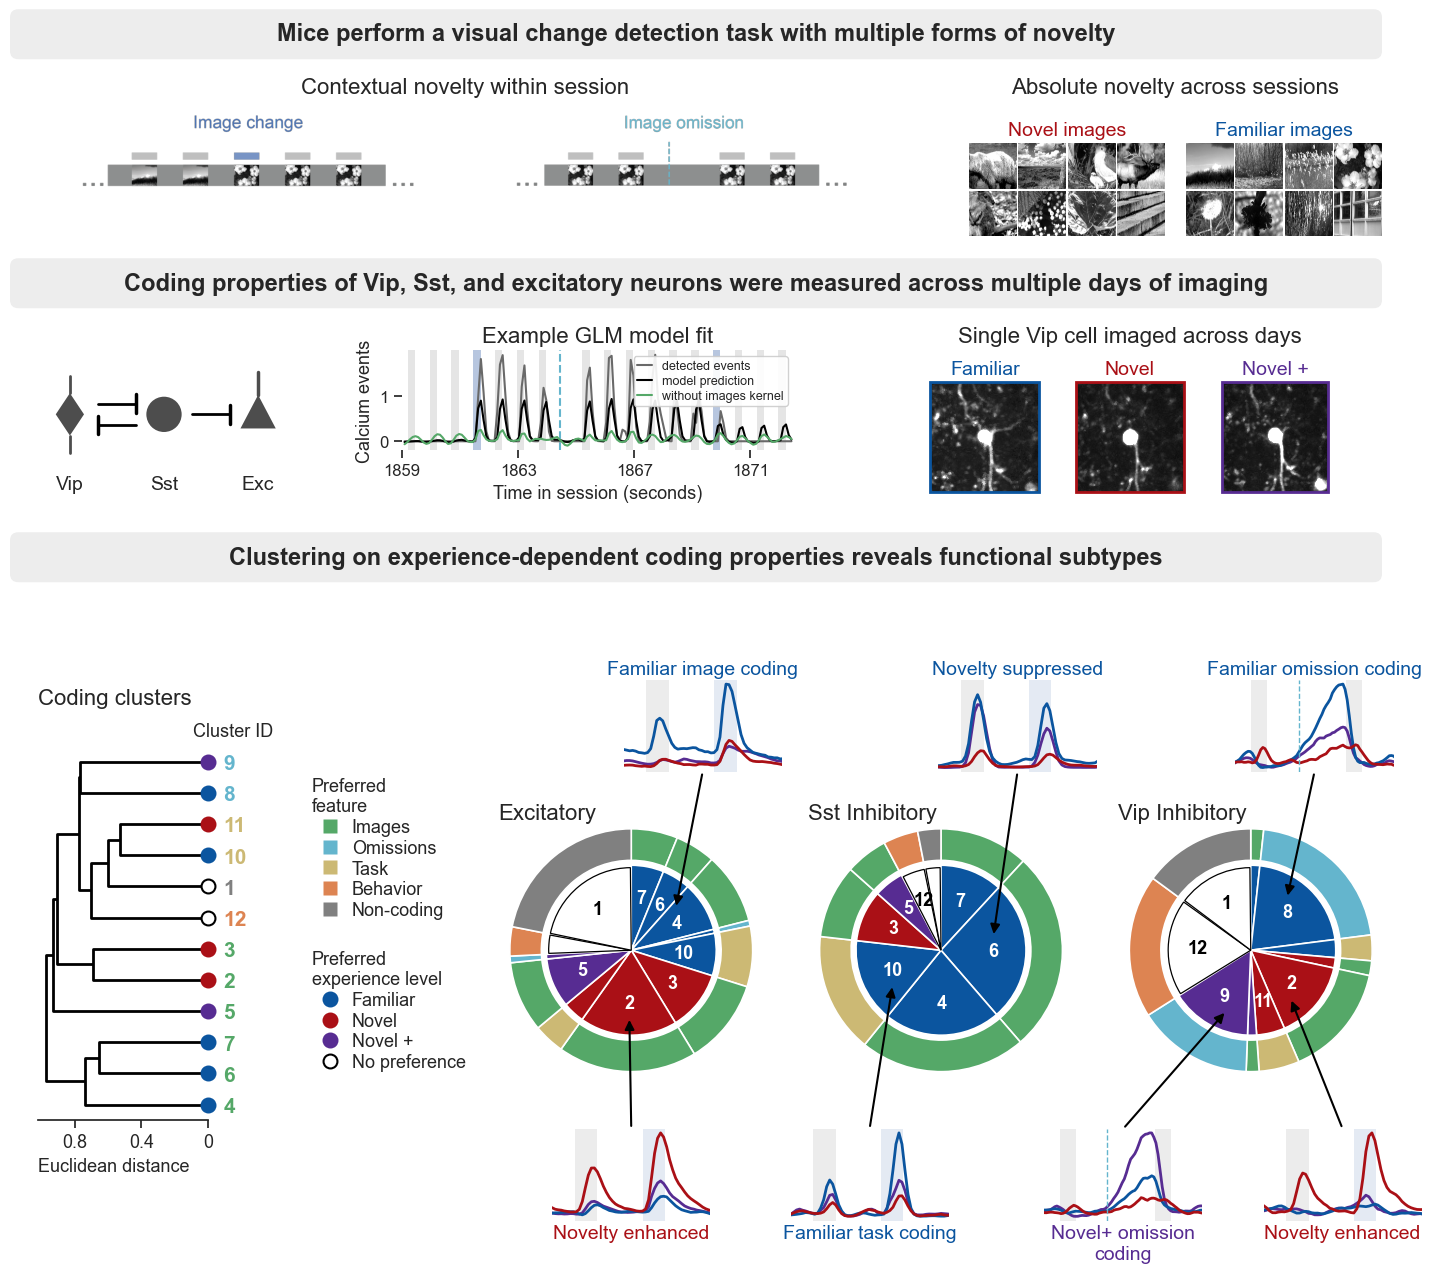

saved /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/Final Figures/platform_paper_figures/graphical_abstract_v2/graphical_abstract_v2_results_only


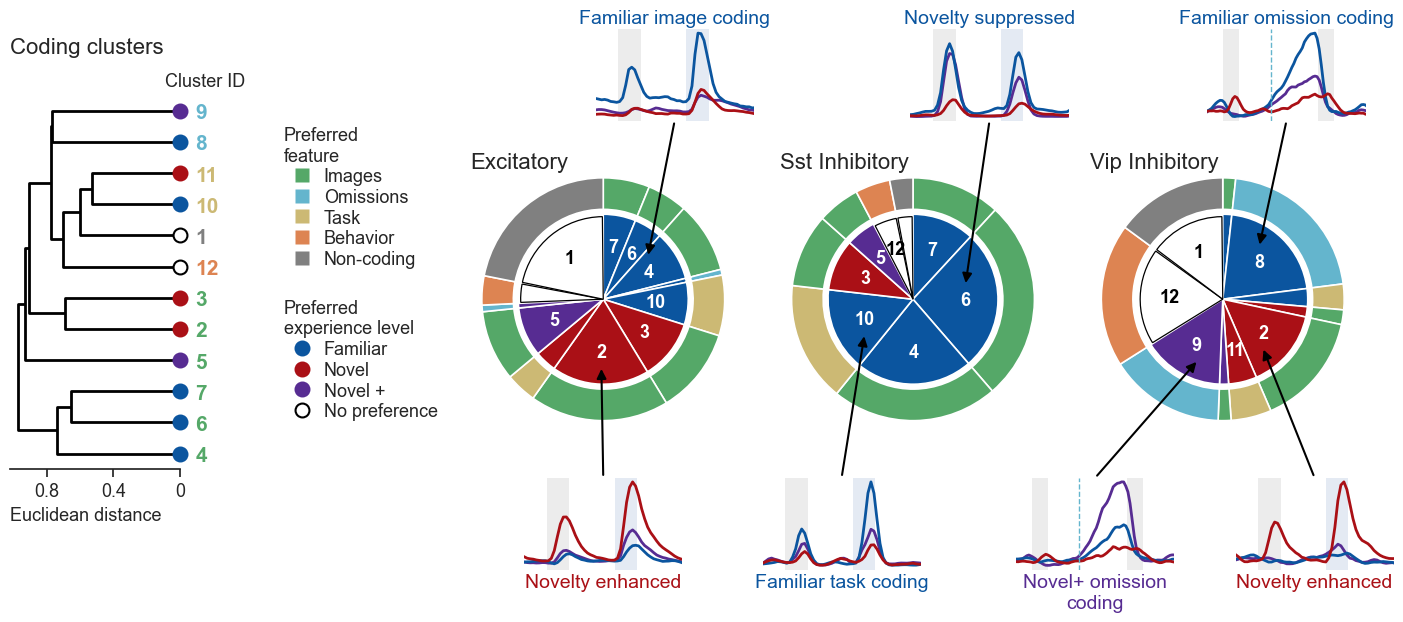

In [20]:
# ---- Graphical abstract v2: cluster dendrogram + cell-type pies (no UMAP) ----
# Dendrogram = same as Figure 5 (cluster-mean coding scores, Euclidean, average linkage); ID labels colored
# by preferred feature, leaf dots by preferred experience (open circle = no preference).
# Pies = % of each cell type's cells in each cluster, ONE WEDGE PER CLUSTER, clockwise from 12 o'clock.
# PIE_ORDER='experience': wedges grouped by preferred experience (Familiar, Novel, Novel +, none), then by preferred
# feature (images, omissions, task, behavior, non-coding), ties broken by dendrogram order.
# PIE_ORDER='dendrogram': wedges follow the dendrogram top -> bottom.
# Each wedge carries both codes: PIE_FILL colors the body, the other code colors a thin outer ring.
# Example traces: cluster-average change/omission responses for ONE cell type, placed above/below that cell type's
# pie (TRACE_CONFIG) with a leader line to the cluster's wedge. Omission clusters are omission-aligned, the rest
# change-aligned. Traces need change_mdf / omission_mdf from the trace data-load cell (skipped if not loaded).
# Trace labels use the functional-type names in CLUSTER_NAMES (cell type is given by the pie the trace points to).
# Experimental design (VERSIONS 'full'): three steps stacked vertically under centered gray headers -- 1) task: the Fig 1
# change / omission schematics ('contextual novelty') + Novel / Familiar image sets ('absolute novelty') (PNG files in SCHEM_DIR); 2) coding: Vip/Sst/Exc circuit diagram,
# example GLM model fit (Fig 4 Cell 1) and one Vip cell's ROI across sessions; 3) clustering, which heads the
# dendrogram + pies panel. 'results_only' saves the dendrogram + pies + traces alone.
# Needs the cell above (cluster_info, leaf_order, dendro_Z, dendro_labels, pie_fracs).
import matplotlib.gridspec as gridspec
from matplotlib.patches import Wedge
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgb
from matplotlib.patches import ConnectionPatch, FancyBboxPatch

# ---------------- knobs ----------------
PIE_FILL      = 'experience' # 'experience' -> body = experience, ring = feature ; 'feature' -> swapped
PIE_ORDER     = 'experience' # 'experience' (group by experience, then feature) | 'dendrogram'
RING_W        = 0.26         # outer ring width (fraction of pie radius)
RING_GAP      = 0.04         # white gap between ring and body (0 = touching)
HOLE          = 0.0          # donut hole in the body (fraction of radius; 0 = solid)
SEP_LW        = 1.2          # white separator between wedges (keeps same-colored neighbouring clusters distinct)
LABEL_IDS     = True         # print cluster IDs on wedges large enough to hold them
LABEL_MIN     = 0.045        # min fraction of a pie for a wedge to get its ID
FS            = 16           # base font size
TITLE_FS      = 16           # panel titles (Coding clusters, cell types, model fit, Vip cell, novelty groups)
LABEL_FS      = 13           # axis / tick labels, legends, small labels -- shared by every panel
# vertical layout (inches): step-1 header + row, step-2 header + row, step-3 header, then the main panel
H_HEAD, H_ROW1, H_ROW2, H_GAP = 0.5, 1.75, 2.0, 0.12
MAIN_OVERLAP  = 0.45         # main panel's empty top margin slides up under the step-3 header (inches)
H_MAIN        = 8.5          # dendrogram + pies + traces (unchanged from before)
FIG_W         = 14
_H_TOP        = 3 * H_HEAD + H_ROW1 + H_ROW2 + 4 * H_GAP - MAIN_OVERLAP
DENDRO_Y      = (0.30, 0.74)  # dendrogram bottom/top (fraction of the main panel; was 0.20-0.80)
PIE_Y         = (0.35, 0.65)   # pie row bottom/top (fraction of the main panel; was 0.30-0.70) -- traces scale with the pies
LEG_X         = 0.38         # legend column left edge, as a fraction of its axes (clears the dendrogram IDs)
LEG_TOP       = 0.84         # top of the legends (axes fraction; lower = closer to the dendrogram's vertical middle)
# traces: {cell_type: [(cluster_id, 'above' | 'below', x_center)]}, x_center in pie-axes fraction (0.5 = centered)
# shift x_center toward the side the wedge is on so the leader line doesn't cross the pie
TRACE_CONFIG  = {'Excitatory':     [(4, 'above', 0.78), (2, 'below', 0.50)],
                 'Sst Inhibitory': [(6, 'above', 0.80), (10, 'below', 0.22)],
                 'Vip Inhibitory': [(8, 'above', 0.75), (9, 'below', 0.00), (2, 'below', 0.86)]}
TRACE_W, TRACE_H = 0.62, 0.36  # trace size (pie-axes fraction)
TRACE_GAP     = 0.20         # gap between pie axes edge and trace (pie-axes fraction); above traces also clear the title
LEADER_LW     = 1.5
CID_OFFSET    = (18, 4)      # 'Cluster ID' header offset (points) from the top of the ID column
TITLE_PAD     = 30           # 'Cluster similarity' title pad (points), leaves room for the 'Cluster ID' header
ARROW_OFFSET  = 0.14         # arrow tip sits this far above/below the wedge's ID label (pie radius units)
ARROW_COLOR   = 'k'
ARROW_TIP_DXY = None         # arrow tip offset from the wedge's ID label (pie radius units), {'above': (dx, dy), 'below': (dx, dy)}; None = (0, +/-ARROW_OFFSET)
ARROW_X_ABOVE = 0.5          # x (trace-axes fraction) where arrows from traces ABOVE a pie start; 0.5 = centre
TITLE_XY      = (-0.02, 1.0)  # cell-type name position (pie-axes fraction, bottom-left anchor)
# functional-type names used as trace labels (from the original graphical abstract); '\n' wraps a long label
CLUSTER_NAMES = {1: 'Non-coding', 2: 'Novelty enhanced', 3: 'Novel image coding', 4: 'Familiar image coding',
                 5: 'Novel image coding', 6: 'Novelty suppressed', 7: 'Unselective', 8: 'Familiar omission coding',
                 9: 'Novel+ omission\ncoding', 10: 'Familiar task coding', 11: 'Novel task coding', 12: 'Behavior coding'}
TRACE_LABEL_FS = LABEL_FS + 1
TRACE_LW      = 2.0          # line width of the example traces
# ---- experimental design: three numbered steps stacked vertically; step 3 heads the main panel ----
# Two versions are saved: 'full' (design steps 1-3 + results) and 'results_only' (dendrogram + pies + traces)
VERSIONS      = {'full': True, 'results_only': False}
DESIGN_STEPS  = ['Mice perform a visual change detection task with multiple forms of novelty',
                 'Coding properties of Vip, Sst, and excitatory neurons were measured across multiple days of imaging',
                 'Clustering on experience-dependent coding properties reveals functional subtypes']
HEAD_FC       = '0.93'         # step header band color
HEAD_FS       = FS + 1         # header text, centered in the gray band
# step 1 row (x0, x1 in figure fraction): Fig 1 change / omission schematics, then the Novel + Familiar image sets
CHANGE_X, OMIT_X = (0.06, 0.30), (0.37, 0.61)
NOVEL_X, FAM_X = (0.695, 0.835), (0.85, 0.99)
GROUP_LABELS  = {'contextual': 'Contextual novelty within session', 'absolute': 'Absolute novelty across sessions'}
GROUP_H       = 0.42           # inches reserved at the top of row 1 for the group labels
SCHEM_DIR     = os.path.join(loading.get_platform_analysis_cache_dir(), 'schematics', 'Figure 1')
SCHEM_FILES   = {'change': 'image_change_small.png', 'omission': 'image_omission_small.png'}   # no timing labels
# step 2 row: circuit diagram | example GLM model fit (Fig 4 Cell 1) | one Vip cell imaged across days
CIRCUIT_X     = (0.02, 0.22)
FIT_X         = (0.29, 0.57)
CELL_X        = (0.66, 0.96)
CELL_H        = 0.55         # ROI image height (fraction of the step-2 row)
CELL_Y0       = 0.14         # ROI image bottom (fraction of the step-2 row; higher = images sit higher)
FIT_XLIM      = [1859, 1859 + 12 * 0.75 + 4.5]   # same window as Fig 4B
FIT_TITLE     = 'Example GLM model fit'
FIT_LEGEND_FS = LABEL_FS - 4
EXAMPLE_CELL_ID = 1086628708   # MUST be a Vip cell for the 'Single Vip cell' title -- see the printout
CELL_TITLE    = 'Single Vip cell imaged across days'
CELL_COLOR    = '0.3'
SAVE          = True

ci = cluster_info
NOPREF_FACE, NOPREF_EDGE = 'white', 'k'


def _ok(col):
    return col is not None and not (isinstance(col, float) and np.isnan(col))   # pandas may turn None into NaN


def _cols(c):
    """(body color, ring color) for a cluster; None = no preference."""
    f, e = ci.loc[c, 'feature_color'], ci.loc[c, 'exp_color']
    f, e = (f if _ok(f) else None), (e if _ok(e) else None)
    return (f, e) if PIE_FILL == 'feature' else (e, f)


def _text_color(col):
    r, g, b = to_rgb(col)
    return 'k' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'w'


def pie_order():
    if PIE_ORDER == 'dendrogram':
        return list(leaf_order)
    exp_rank = {lvl: i for i, lvl in enumerate(exp_levels)}
    feat_rank = {f: i for i, f in enumerate(features)}
    key = lambda c: (exp_rank.get(ci.loc[c, 'preferred_experience'], len(exp_levels)),   # no preference last
                     len(features) if ci.loc[c, 'feature_color'] == feature_cols[0]          # non-coding last
                     else feat_rank[ci.loc[c, 'dominant_feature']],
                     ci.loc[c, 'dendro_rank'])
    return sorted(ci.index, key=key)


def draw_dendrogram(ax):
    d = dendrogram(dendro_Z, labels=dendro_labels, ax=ax, orientation='left', link_color_func=lambda k: 'k')
    for ln in ax.collections:
        ln.set_linewidth(2)
    for j, leaf in enumerate(d['leaves']):
        col = ci.loc[dendro_labels[leaf], 'exp_color']
        col = col if _ok(col) else None
        ax.plot(0, 5 + 10 * j, 'o', ms=10, mew=1.5, clip_on=False, zorder=4,
                mfc=col if col is not None else 'white', mec=col if col is not None else 'k')
    ax.tick_params(axis='y', length=0, pad=11, labelsize=LABEL_FS + 2)
    # 'Cluster ID' header just above the column of ID labels (x = right edge of the axes + the tick-label pad)
    ax.annotate('Cluster ID', xy=(1.0, 10 * len(dendro_labels)), xycoords=('axes fraction', 'data'),
                xytext=CID_OFFSET, textcoords='offset points', ha='center', va='bottom', fontsize=LABEL_FS)
    for t in ax.get_yticklabels():
        t.set_color(ci.loc[int(t.get_text()), 'feature_color']); t.set_fontweight('bold')
    ax.set_xticks([0, 0.4, 0.8]); ax.set_xticklabels(['0', '0.4', '0.8'], fontsize=LABEL_FS)
    ax.set_xlabel('Euclidean distance', fontsize=LABEL_FS, loc='left')
    ax.set_title('Coding clusters', fontsize=TITLE_FS, loc='left', pad=TITLE_PAD)   # raised to clear 'Cluster ID'
    sns.despine(ax=ax, left=True)


def _label_r():
    """radius of the wedge ID labels (arrows point here too)"""
    r_body = 1 - RING_W - RING_GAP
    return (HOLE + r_body) / 2 if HOLE else r_body * 0.62


def draw_pie(ax, fracs, title):
    """fracs: Series indexed by cluster_id, in wedge order; clockwise from 12 o'clock.
    Returns {cluster_id: mid-angle in degrees} for leader lines."""
    mid = {}
    r_body = 1 - RING_W - RING_GAP
    theta = 90.0
    for c, f in fracs.items():
        if f <= 0:
            continue
        t1, t0 = theta, theta - 360 * f                   # clockwise
        body, ring = _cols(c)
        if body is not None:
            ax.add_patch(Wedge((0, 0), r_body, t0, t1, width=r_body - HOLE if HOLE else None,
                               fc=body, ec='white', lw=SEP_LW))
        else:   # no preference: open wedge, like the open dendrogram dot
            ax.add_patch(Wedge((0, 0), r_body - 0.02, t0 + 0.6, t1 - 0.6,
                               width=(r_body - HOLE - 0.04) if HOLE else None, fc=NOPREF_FACE, ec=NOPREF_EDGE, lw=0.9))
        if ring is not None:
            ax.add_patch(Wedge((0, 0), 1, t0, t1, width=RING_W, fc=ring, ec='white', lw=SEP_LW))
        else:   # no preference: open ring, like the open dendrogram dot
            ax.add_patch(Wedge((0, 0), 1 - 0.02, t0 + 0.6, t1 - 0.6, width=RING_W - 0.04,
                               fc=NOPREF_FACE, ec=NOPREF_EDGE, lw=0.9))
        if LABEL_IDS and f >= LABEL_MIN:
            a = np.deg2rad((t0 + t1) / 2)
            rr = _label_r()
            ax.text(rr * np.cos(a), rr * np.sin(a), str(c), ha='center', va='center', fontsize=FS - 3,
                    fontweight='bold', color=_text_color(body if body is not None else 'white'))
        mid[c] = (t0 + t1) / 2
        theta = t0
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05); ax.set_aspect('equal'); ax.axis('off')
    # cell-type name at the pie's top-left (ax.set_title would get pushed above the trace insets)
    ax.text(TITLE_XY[0], TITLE_XY[1], title, transform=ax.transAxes, ha='left', va='bottom', fontsize=TITLE_FS)
    return mid


def _plot_cluster_trace(ax, cell_type, cluster_id):
    """Mean response of one cluster's cells of one cell type, per experience level (same style as Fig 5).
    Omission clusters are omission-aligned, all others change-aligned."""
    omitted = ci.loc[cluster_id, 'dominant_feature'] == 'omissions'
    mdf = omission_mdf if omitted else change_mdf
    csids = cluster_meta.index[(cluster_meta.cluster_id == cluster_id) & (cluster_meta.cell_type == cell_type)]
    sub = mdf[mdf.cell_specimen_id.isin(csids)]
    ts = mdf['trace_timestamps'].values[0]
    for i in [2, 0, 1]:                       # Novel + (back), Familiar, Novel (front) -- as in the old abstract
        tr = sub[sub.experience_level == exp_levels[i]].mean_trace.values
        if len(tr):
            utils.plot_mean_trace(np.asarray(tr), ts, ylabel='', legend_label=None, color=exp_cols[i],
                                  interval_sec=1, plot_sem=False, linewidth=TRACE_LW, xlim_seconds=[-1, 1.5] if omitted else [-1, 0.75], ax=ax)
    utils.plot_flashes_on_trace(ax, ts, change=not omitted, omitted=omitted, alpha=0.15)
    ax.set_xlabel(''); ax.set_ylabel(''); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)


def add_traces(pax, cell_type, mid):
    """Trace insets above/below a pie, each with a leader line to its cluster's wedge."""
    have_data = ('change_mdf' in globals()) and ('omission_mdf' in globals())
    plot_fn = globals().get('trace_fn_override', _plot_cluster_trace if have_data else None)
    for cid, where, xc in TRACE_CONFIG.get(cell_type, []):
        y0 = 1 + TRACE_GAP if where == 'above' else -TRACE_GAP - TRACE_H
        tax = pax.inset_axes([xc - TRACE_W / 2, y0, TRACE_W, TRACE_H])
        if plot_fn is not None:
            plot_fn(tax, cell_type, cid)
        else:
            tax.text(0.5, 0.5, 'trace\n(load data)', ha='center', va='center', fontsize=FS - 4, color='0.5')
            tax.set_xticks([]); tax.set_yticks([])
        e = ci.loc[cid, 'exp_color']
        # label on the side away from the pie, so the leader line doesn't cross it
        tax.text(0.5, 1.02 if where == 'above' else -0.04, CLUSTER_NAMES.get(cid, f'cluster {cid}'),
                 transform=tax.transAxes, ha='center', va='bottom' if where == 'above' else 'top',
                 fontsize=TRACE_LABEL_FS, color=e if _ok(e) else 'k')
        if cid not in mid:
            print(f'{cell_type}: cluster {cid} has no cells -- no leader line'); continue
        a = np.deg2rad(mid[cid])
        # arrow from the trace to the wedge centre, ending just above (trace above) / below (trace below) the ID label
        dxy = (ARROW_TIP_DXY or {'above': (0, ARROW_OFFSET), 'below': (0, -ARROW_OFFSET)})[where]
        tip = (_label_r() * np.cos(a) + dxy[0], _label_r() * np.sin(a) + dxy[1])
        fig.add_artist(ConnectionPatch(xyA=(ARROW_X_ABOVE if where == 'above' else 0.5, 0 if where == 'above' else 1), coordsA=tax.transAxes,
                                       xyB=tip, coordsB=pax.transData, color=ARROW_COLOR, lw=LEADER_LW, zorder=6,
                                       arrowstyle='-|>', mutation_scale=14, shrinkA=2, shrinkB=0))


def draw_legends(ax):
    ax.axis('off')
    hF = [Line2D([], [], marker='s', ls='', ms=10, mfc=c, mec='none') for c in list(feature_cols[1:5]) + [feature_cols[0]]]
    lgF = ax.legend(hF, ['Images', 'Omissions', 'Task', 'Behavior', 'Non-coding'],
                    title='Preferred\nfeature', loc='upper left', bbox_to_anchor=(LEG_X, LEG_TOP),
                    fontsize=LABEL_FS, title_fontsize=LABEL_FS, frameon=False, handletextpad=0.2, labelspacing=0.15,
                    borderpad=0, borderaxespad=0)
    lgF._legend_box.align = 'left'
    ax.add_artist(lgF)
    ax.figure.canvas.draw()
    y = ax.transAxes.inverted().transform(lgF.get_window_extent())[0, 1] - 0.06
    hE = ([Line2D([], [], marker='o', ls='', ms=10, mew=1.5, mfc=c, mec=c) for c in exp_cols[:3]]
          + [Line2D([], [], marker='o', ls='', ms=10, mew=1.5, mfc='white', mec='k')])
    lgE = ax.legend(hE, list(exp_levels) + ['No preference'],
                    title='Preferred\nexperience level', loc='upper left', bbox_to_anchor=(LEG_X, y),
                    fontsize=LABEL_FS, title_fontsize=LABEL_FS, frameon=False, handletextpad=0.2, labelspacing=0.15,
                    borderpad=0, borderaxespad=0)
    lgE._legend_box.align = 'left'



def _yf(inches_from_top):
    """figure-fraction y for a distance (inches) measured down from the top of the figure"""
    return 1 - inches_from_top / FIGSIZE[1]


def _step_header(i, y_top_in):
    """numbered gray header band for step i, spanning the figure width, top edge y_top_in inches from the top"""
    y0, y1 = _yf(y_top_in + H_HEAD), _yf(y_top_in)
    fig.add_artist(FancyBboxPatch((0.01, y0), 0.98, y1 - y0, boxstyle='round,pad=0,rounding_size=0.006',
                                  transform=fig.transFigure, fc=HEAD_FC, ec='none', zorder=0))
    fig.text(0.5, (y0 + y1) / 2, DESIGN_STEPS[i], ha='center', va='center', fontsize=HEAD_FS, fontweight='bold')


def _image_ax(x, y_bottom, y_top, img):
    """axes showing an image at its own aspect, as large as fits in [x0, x1] x [y_bottom, y_top], top-aligned"""
    w, h = x[1] - x[0], y_top - y_bottom
    a = fig.add_axes([x[0], y_bottom, w, h]); a.imshow(img); a.set_anchor('N'); a.axis('off')
    return a


def _draw_stim_grid(x, y_bottom, y_top, templates, title, color):
    """2x4 grid of stimulus images (from the original abstract), title above"""
    top = y_top - 0.30 / FIGSIZE[1]                            # room for the title
    g = fig.add_gridspec(2, 4, left=x[0], right=x[1], bottom=y_bottom + 0.1 / FIGSIZE[1], top=top, wspace=0.04, hspace=0.04)
    for i, name in enumerate(np.sort(templates.index)[:8]):
        a = fig.add_subplot(g[i // 4, i % 4])
        im = templates.loc[name]['unwarped'].copy(); im[np.isnan(im)] = 150
        a.imshow(im, cmap='gray', aspect='auto'); a.set_xlim(480, 1400); a.set_ylim(220, 980)
        a.invert_yaxis(); a.axis('off')
    fig.text((x[0] + x[1]) / 2, top + 0.04 / FIGSIZE[1], title, ha='center', va='bottom', color=color, fontsize=LABEL_FS + 1)


def _cell_glyph(ax, xy, kind, size=0.075):
    x, y = xy
    if kind == 'Exc':
        ax.add_patch(plt.Polygon([(x - size, y - size * 0.8), (x + size, y - size * 0.8), (x, y + size * 1.1)],
                                 fc=CELL_COLOR, ec='none', zorder=3))
        ax.plot([x, x], [y + size * 1.1, y + size * 2.4], color=CELL_COLOR, lw=2.5, zorder=2)   # apical dendrite
    elif kind == 'Sst':
        ax.add_patch(plt.Circle((x, y), size, fc=CELL_COLOR, ec='none', zorder=3))
    else:   # Vip: diamond with vertical processes
        ax.add_patch(plt.Polygon([(x, y + size * 1.2), (x + size * 0.8, y), (x, y - size * 1.2), (x - size * 0.8, y)],
                                 fc=CELL_COLOR, ec='none', zorder=3))
        ax.plot([x, x], [y + size * 1.2, y + size * 2.2], color=CELL_COLOR, lw=2, zorder=2)
        ax.plot([x, x], [y - size * 1.2, y - size * 2.2], color=CELL_COLOR, lw=2, zorder=2)


def _inhib(ax, p0, p1, shrink=0.12, offset=0.0):
    """inhibitory connection p0 -| p1 (line ending in a T-bar), shifted sideways by offset"""
    p0, p1 = np.array(p0, float), np.array(p1, float)
    d = (p1 - p0) / np.linalg.norm(p1 - p0)
    perp = np.array([-d[1], d[0]])
    a, b = p0 + d * shrink + perp * offset, p1 - d * shrink + perp * offset
    ax.plot(*zip(a, b), color='k', lw=2, zorder=1)
    ax.plot(*zip(b - perp * 0.04, b + perp * 0.04), color='k', lw=2.5, zorder=1)


def draw_circuit(ax):
    """Vip -| Sst (reciprocal) and Sst -| Exc, cells in a row: Vip, Sst, Exc."""
    pos = {'Vip': (0.10, 0.45), 'Sst': (0.50, 0.45), 'Exc': (0.90, 0.45)}
    for k, p in pos.items():
        _cell_glyph(ax, p, k)
        ax.text(p[0], p[1] - 0.26, k, ha='center', va='top', fontsize=LABEL_FS + 1)
    _inhib(ax, pos['Vip'], pos['Sst'], offset=0.045)
    _inhib(ax, pos['Sst'], pos['Vip'], offset=0.045)
    _inhib(ax, pos['Sst'], pos['Exc'])
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(0.0, 0.85); ax.set_aspect('equal'); ax.set_anchor('C'); ax.axis('off')


def _draw_model_fit(ax):
    """Fig 4 'Cell 1' model fit (needs gep + fit_dataset / fit_glm from the model-fit data-load cell)."""
    import visual_behavior.visualization.ophys.glm_example_plots as gep
    cell_results_df, expt_results, dropouts = fit_glm
    gep.plot_model_fits_example_cell(cell_specimen_id=FIT_CELL['cell_id'], dataset=fit_dataset,
                                     cell_results_df=cell_results_df, dropouts=dropouts, results=expt_results,
                                     kernel='all-images', include_events=True, include_dff=False, times=FIT_XLIM,
                                     title='', twinx=False, fontsize=LABEL_FS - 2, ax=ax)
    # match the rest of the abstract: smaller axis / tick / legend text than the function's defaults
    ax.set_title(FIT_TITLE, fontsize=TITLE_FS)
    ax.xaxis.label.set_fontsize(LABEL_FS); ax.yaxis.label.set_fontsize(LABEL_FS)
    ax.tick_params(labelsize=LABEL_FS - 1)
    # rebuild the legend: label the gray detected-events trace and shorten the dropout label
    from matplotlib.colors import to_hex
    lines = {ln.get_label(): ln for ln in ax.get_lines()}
    ev = [ln for ln in ax.get_lines() if to_hex(ln.get_color()) == to_hex('dimgray')]
    pred = lines.get('model prediction')
    drop = [ln for lab, ln in lines.items() if 'drop in VE' in lab]
    handles, labels = [], []
    for h, lab in [(ev[0] if ev else None, 'detected events'), (pred, 'model prediction'),
                   (drop[0] if drop else None, 'without images kernel')]:
        if h is not None:
            handles.append(h); labels.append(lab)
    ax.legend(handles, labels, loc='upper right', fontsize=FIT_LEGEND_FS, frameon=True, framealpha=0.9,
              handlelength=1.2, borderpad=0.3, labelspacing=0.2)


def _draw_example_cell(rect):
    """One cell's ROI in the Familiar / Novel / Novel + sessions (pse.plot_matched_rois sets colored titles)."""
    import visual_behavior.visualization.ophys.platform_single_cell_examples as pse
    ct = cluster_meta.cell_type.get(EXAMPLE_CELL_ID, 'not in cluster_meta')
    print(f'example cell {EXAMPLE_CELL_ID}: {ct} (cluster {cluster_meta.cluster_id.get(EXAMPLE_CELL_ID, "?")})')
    if ct != 'Vip Inhibitory':
        cand = cluster_meta[(cluster_meta.cell_type == 'Vip Inhibitory') & (cluster_meta.cluster_id == 2)].index[:10]
        print('  -> not a Vip cell. Some Vip cells in cluster 2 (novelty enhanced) to try:', list(cand))
    g = fig.add_gridspec(1, 3, left=rect[0], right=rect[0] + rect[2], bottom=rect[1], top=rect[1] + rect[3], wspace=0.12)
    axs = [fig.add_subplot(g[0, i]) for i in range(3)]
    pse.plot_matched_rois(EXAMPLE_CELL_ID, platform_cells_table, save_dir=None, ax=axs)
    for a, col in zip(axs, exp_cols):
        a.title.set_fontsize(LABEL_FS + 1)
        a.add_patch(plt.Rectangle((0, 0), 1, 1, transform=a.transAxes, fill=False, edgecolor=col, lw=2,
                                  clip_on=False, zorder=10))


def draw_design():
    """Step 1 header + image sets / task schematics, step 2 header + circuit / model fit / example cell,
    step 3 header over the main panel."""
    mock = globals().get('design_override')               # mock-up hook (image files); unused in the real run
    exp_c = dict(zip(exp_levels, exp_cols))
    y = H_GAP
    # ---- step 1: image sets + change / omission schematics ----
    _step_header(0, y); y += H_HEAD + H_GAP
    rb, rt_row = _yf(y + H_ROW1), _yf(y)
    rt = _yf(y + GROUP_H)                                   # content sits under the group labels
    for key, (xa, xb) in [('contextual', (CHANGE_X[0], OMIT_X[1])), ('absolute', (NOVEL_X[0], FAM_X[1]))]:
        ylab = rt_row - 0.06 / FIGSIZE[1]
        fig.text((xa + xb) / 2, ylab, GROUP_LABELS[key], ha='center', va='top', fontsize=TITLE_FS)
    if mock:
        mock['grids'](fig, rb, rt)
    elif ('novel_templates' in globals()) and ('familiar_templates' in globals()):
        _draw_stim_grid(NOVEL_X, rb, rt, novel_templates, 'Novel images', exp_c[NOV])
        _draw_stim_grid(FAM_X, rb, rt, familiar_templates, 'Familiar images', exp_c[FAM])
    else:
        print('stimulus templates not loaded -- run the stimulus-image load cell for the step-1 image sets')
    for kind, x in [('change', CHANGE_X), ('omission', OMIT_X)]:
        path = mock['schem'][kind] if mock else os.path.join(SCHEM_DIR, SCHEM_FILES[kind])
        _image_ax(x, rb, rt, plt.imread(path))
    y += H_ROW1 + H_GAP
    # ---- step 2: circuit | model fit | Vip cell across days ----
    _step_header(1, y); y += H_HEAD + H_GAP
    rb, rt = _yf(y + H_ROW2), _yf(y)
    draw_circuit(fig.add_axes([CIRCUIT_X[0], rb, CIRCUIT_X[1] - CIRCUIT_X[0], rt - rb]))
    fit_rect = [FIT_X[0], rb + 0.35 * (rt - rb), FIT_X[1] - FIT_X[0], 0.5 * (rt - rb)]
    if mock:
        mock['fit'](fig, fit_rect)
    elif 'fit_glm' in globals():
        _draw_model_fit(fig.add_axes(fit_rect))
    else:
        print('model-fit data not loaded -- run the model-fit load cell for the step-2 example fit')
    cell_rect = [CELL_X[0], rb + CELL_Y0 * (rt - rb), CELL_X[1] - CELL_X[0], CELL_H * (rt - rb)]
    if mock:
        mock['cell'](fig, cell_rect)
    else:
        _draw_example_cell(cell_rect)
    fig.text((CELL_X[0] + CELL_X[1]) / 2, rt - 0.004, CELL_TITLE, ha='center', va='top', fontsize=TITLE_FS)
    y += H_ROW2 + H_GAP
    # ---- step 3 heads the main panel ----
    _step_header(2, y)


def make_figure(show_design):
    """Build the figure; the main panel keeps its H_MAIN height, the design steps (if shown) are stacked above it."""
    global fig, FIGSIZE, MAIN_TOP
    FIGSIZE = (FIG_W, H_MAIN + (_H_TOP if show_design else 0))
    MAIN_TOP = H_MAIN / FIGSIZE[1]                      # main panel uses figure y in [0, MAIN_TOP]
    fig = plt.figure(figsize=FIGSIZE)
    gs_l = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.0, 1.25], wspace=0.12,
                             left=0.03, right=0.32, top=0.80 * MAIN_TOP, bottom=0.20 * MAIN_TOP)   # legend column
    gs_d = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.0, 1.25], wspace=0.12, left=0.03, right=0.32,
                             top=DENDRO_Y[1] * MAIN_TOP, bottom=DENDRO_Y[0] * MAIN_TOP)        # dendrogram (shorter)
    gs_p = gridspec.GridSpec(1, 3, figure=fig, wspace=0.18, left=0.36, right=0.99,
                             top=PIE_Y[1] * MAIN_TOP, bottom=PIE_Y[0] * MAIN_TOP)              # pies (traces above/below)
    ax_d, ax_l = fig.add_subplot(gs_d[0]), fig.add_subplot(gs_l[1])
    ax_p = [fig.add_subplot(gs_p[i]) for i in range(3)]
    draw_dendrogram(ax_d)
    draw_legends(ax_l)
    for a, ct in zip(ax_p, cell_types):
        mid = draw_pie(a, pie_fracs.loc[ct, order], ct)
        add_traces(a, ct, mid)
    if show_design:
        draw_design()
    return fig


order = pie_order()
print('pie wedge order (clockwise from 12 o\'clock):', order)
for version, show_design in VERSIONS.items():
    fig = make_figure(show_design)
    if SAVE:
        name = f'graphical_abstract_v2_{version}'
        for ext in ['png', 'pdf']:
            fig.savefig(os.path.join(save_dir, f'{name}.{ext}'), dpi=300, bbox_inches='tight')
        print('saved', os.path.join(save_dir, name))
    plt.show()

### Composite 'simple': task schematic + images / cell across sessions + results

Saves `graphical_abstract_v2_simple.{png,pdf}`. Top part (no gray header bands): suptitle, the Figure 1 change detection schematic (`schematics/Figure 1/cd_schematic.png`) and a block with one column per session type (Familiar / Novel / Novel +): an example image (flowers = familiar, moose = novel; row title 'Familiar and novel images shown in different sessions') above one Vip cell's ROI in that session (row title 'Single cells tracked across sessions'). Bottom: the v2 results panel (dendrogram, legends, ringed pies, traces), unchanged. Run the composite cell above first (it defines the functions and knobs).

example cell 1086628708: Vip Inhibitory
cell_specimen_id: 1086628708
experience_level: Familiar
ophys_experiment_id: 882551935


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel
ophys_experiment_id: 882968564


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 885146239


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

rendered 11.9 x 11.6 in (w x h); aspect 1.03 (1.00 = square)
4 x 4 in version: everything shrinks to 0.34x -> 13 pt prints at 4.4 pt, 16 pt at 5.4 pt
saved /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/Final Figures/platform_paper_figures/graphical_abstract_v2/graphical_abstract_v2_simple (+ _4x4.tif / _4x4.png)


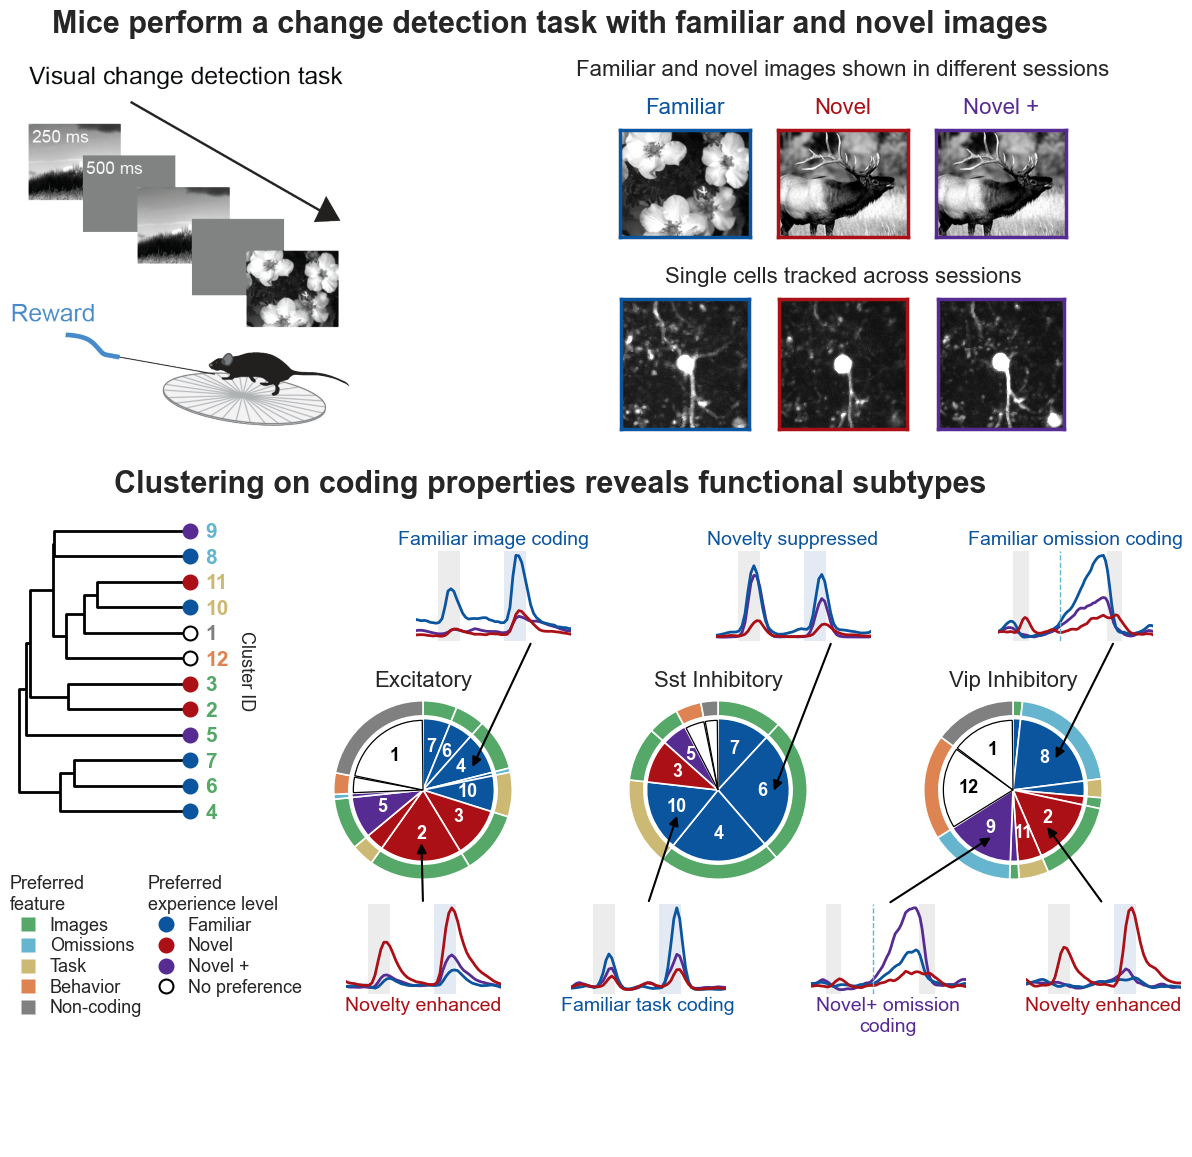

In [21]:
# ---- Graphical abstract v2 'simple': task schematic + images / one cell across sessions, above the v2 results ----
# Top row (no gray header bands): left = Figure 1 change detection schematic (cd_schematic.png); right = a 2 x 3 block
# whose columns are the three session types (Familiar / Novel / Novel +): row 1 = example image shown in that session
# (flowers = familiar, moose = novel, the same novel image for Novel +), row 2 = one Vip cell's ROI in that session
# (EXAMPLE_CELL_ID, as in the 'full' version). Bottom = the v2 results panel (dendrogram + legends + pies + traces),
# unchanged. Re-uses the functions and knobs of the cell above, so run that cell first.
# Saves graphical_abstract_v2_simple.{png,pdf} to save_dir.
import visual_behavior.visualization.ophys.platform_single_cell_examples as pse

# ---------------- knobs (inches, measured from the top-left of the figure) ----------------
CD_SCHEMATIC   = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'schematics', 'Figure 1',
                              'cd_schematic.png')
IMAGE_SETS_DIR = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'figure_1', 'image_sets')
# example image per session type: (Figure 1 image-set PNG, tile row, tile col); tile pixel bounds below
KEY_TILES      = {'Familiar': ('Familiar_images.png', 0, 3), 'Novel': ('Novel_images.png', 0, 3),
                  'Novel +': ('Novel_images.png', 0, 3)}
TILE_ROWS      = [(239, 595), (723, 1079)]
TILE_COLS      = [(30, 462), (506, 938), (982, 1414), (1457, 1889)]
S_TOP_GAP      = 0.15                     # figure top -> top row
S_SUPTITLE     = 'Mice perform a change detection task with familiar and novel images'
S_SUPTITLE_H   = 0.50                     # suptitle line above the top row
S_TOP_ROW      = 4.30                     # height of the top part (suptitle + schematic / images / cell)
S_HEAD_H       = 0.55                     # results header line
S_HEAD_TEXT    = 'Clustering on coding properties reveals functional subtypes'
S_HEAD_FS      = 22                       # the two bold section titles (the 'full' version uses HEAD_FS = 17)
S_FIG_W        = 12.0                     # figure width (the 'full' version uses FIG_W = 14)
S_MAIN_OVERLAP = 1.30                     # results panel's empty top margin slides up under its title
SCHEM_BOX      = (0.6, 4.0)               # x0, x1 of the schematic (fit inside, keeps its aspect)
BLOCK_X0       = 6.70                     # left edge of the images / cell block
COL_W, COL_GAP = 1.30, 0.28               # block column width and gap
KEY_H          = COL_W * (TILE_ROWS[0][1] - TILE_ROWS[0][0]) / (TILE_COLS[0][1] - TILE_COLS[0][0])
ROW_GAP        = 0.30                     # image row -> cell-row title
ROW_TITLES     = ('Familiar and novel images shown in different sessions', 'Single cells tracked across sessions')
FRAME_LW       = 2.5
PIE_SCALE      = 0.75                     # pie diameter relative to the 'full' version (ring shrinks with it; traces unchanged)
SAVE_SIMPLE    = True
# results panel, left column: dendrogram on top, its two legends side by side below it (figure / panel fractions)
S_LEFT_COL     = (0.05, 0.20)             # dendrogram axes x0, x1 (figure fraction; cluster IDs sit just right of x1)
S_DENDRO_Y     = (0.46, 0.82)             # dendrogram bottom / top (fraction of the results panel)
S_LEG_BOX      = (0.05, 0.30, 0.08, 0.40) # legends x0, x1 (figure fraction), bottom, top (fraction of the results panel)
S_LEG_SPLIT    = 0.46                     # experience legend starts at this fraction of the legend box width
S_PIES_X       = (0.29, 0.99)             # pie row x0, x1 (figure fraction)
S_TRACE_GAP    = {'above': 0.22, 'below': 0.08}   # pie edge -> trace gap (pie-axes fraction); 'above' also clears the cell-type name
S_RING_W       = 0.17                     # feature-ring width (fraction of pie radius; 'full' uses RING_W = 0.26) -> bigger inner pie, same outer size
S_RING_GAP     = 0.03                     # white gap between ring and inner pie ('full' uses RING_GAP = 0.04)
S_ARROW_X_ABOVE = 0.75                    # arrows from the upper traces start right of centre, clear of the cell-type names
S_ARROW_TIP    = {'above': (0.13, 0.0),    # upper traces: arrow ends at the right side of the wedge's ID label
                  'below': (0.0, -0.10)}  # lower traces: just below the ID label (pie radius units)
S_HIDE_IDS     = {'Sst Inhibitory': [12]}  # wedge ID labels to drop (too small to read)
S_CT_TITLE_PAD = 0.02                     # cell-type name: gap above the pie (pie-axes fraction)
S_CID_OFFSET   = 34                       # 'Cluster ID' (vertical, right of the IDs as in Fig 5C): offset from the axes edge (points)
S_HEAD_DY      = 0.30                     # 'Clustering ...' title: distance below the top part (inches)
GA_PX          = 1200                     # Cell Press graphical abstract: 1200 x 1200 px at 300 dpi (4 x 4 in)


def _fx(x_in):                             # inches from the left -> figure fraction
    return x_in / FIGSIZE[0]


def _box(x0, y_top, w, h):                 # axes rect from inches (y measured down from the top)
    return [_fx(x0), _yf(y_top + h), w / FIGSIZE[0], h / FIGSIZE[1]]


def _frame(a, col):
    a.set_axis_on(); a.set_xticks([]); a.set_yticks([]); a.set_title('')
    for sp in a.spines.values():
        sp.set_visible(True); sp.set_edgecolor(col); sp.set_linewidth(FRAME_LW)


def _key_image(level):
    fname, r, c = KEY_TILES[level]
    im = plt.imread(os.path.join(IMAGE_SETS_DIR, fname))
    return im[TILE_ROWS[r][0]:TILE_ROWS[r][1], TILE_COLS[c][0]:TILE_COLS[c][1]]


def draw_design_simple():
    exp_c = dict(zip(exp_levels, exp_cols))
    y0 = S_TOP_GAP
    fig.text(0.5, _yf(y0), S_SUPTITLE, ha='center', va='top', fontsize=S_HEAD_FS, fontweight='bold')
    yc = y0 + S_SUPTITLE_H                                   # top of the schematic / image block
    block_w = 3 * COL_W + 2 * COL_GAP
    xm = BLOCK_X0 + block_w / 2                              # block centre (row titles are centred on it)
    fig.text(_fx(xm), _yf(yc), ROW_TITLES[0], ha='center', va='top', fontsize=TITLE_FS)
    y_lab = yc + 0.38                                        # column labels (session type)
    y_img = y_lab + 0.32                                     # image row top
    y_t2 = y_img + KEY_H + ROW_GAP                           # cell-row title
    y_roi = y_t2 + 0.32                                      # cell row top
    # schematic: as large as fits beside the block (same height), keeping its aspect
    sch = plt.imread(CD_SCHEMATIC)
    a = fig.add_axes(_box(SCHEM_BOX[0], yc, SCHEM_BOX[1] - SCHEM_BOX[0], y_roi + COL_W - yc))
    a.imshow(sch); a.set_anchor('C'); a.axis('off')
    roi_axes = []
    for i, level in enumerate(exp_levels):
        x = BLOCK_X0 + i * (COL_W + COL_GAP)
        fig.text(_fx(x + COL_W / 2), _yf(y_lab), level, ha='center', va='top', fontsize=TITLE_FS,
                 color=exp_c[level])
        a = fig.add_axes(_box(x, y_img, COL_W, KEY_H))
        a.imshow(_key_image(level), cmap='gray', aspect='auto'); _frame(a, exp_c[level])
        roi_axes.append(fig.add_axes(_box(x, y_roi, COL_W, COL_W)))
    fig.text(_fx(xm), _yf(y_t2), ROW_TITLES[1], ha='center', va='top', fontsize=TITLE_FS)
    ct = cluster_meta.cell_type.get(EXAMPLE_CELL_ID, 'not in cluster_meta')
    print(f'example cell {EXAMPLE_CELL_ID}: {ct}')
    pse.plot_matched_rois(EXAMPLE_CELL_ID, platform_cells_table, save_dir=None, ax=roi_axes)
    for a, level in zip(roi_axes, exp_levels):
        _frame(a, exp_c[level])
    if y_roi + COL_W > y0 + S_TOP_ROW:
        print(f'note: top part needs S_TOP_ROW >= {y_roi + COL_W - y0:.2f} in')
    # results suptitle (plain bold text, no gray band)
    fig.text(0.5, _yf(y0 + S_TOP_ROW + S_HEAD_DY), S_HEAD_TEXT, ha='center', va='top', fontsize=S_HEAD_FS,
             fontweight='bold')


def draw_legends_below(ax):
    """Preferred-feature and preferred-experience legends side by side (same entries as draw_legends)."""
    ax.axis('off')
    kw = dict(fontsize=LABEL_FS, title_fontsize=LABEL_FS, frameon=False, handletextpad=0.2, labelspacing=0.15,
              borderpad=0, borderaxespad=0, loc='upper left')
    hF = [Line2D([], [], marker='s', ls='', ms=10, mfc=c, mec='none') for c in list(feature_cols[1:5]) + [feature_cols[0]]]
    lgF = ax.legend(hF, ['Images', 'Omissions', 'Task', 'Behavior', 'Non-coding'], title='Preferred\nfeature',
                    bbox_to_anchor=(0, 1), **kw)
    lgF._legend_box.align = 'left'; ax.add_artist(lgF)
    hE = ([Line2D([], [], marker='o', ls='', ms=10, mew=1.5, mfc=c, mec=c) for c in exp_cols[:3]]
          + [Line2D([], [], marker='o', ls='', ms=10, mew=1.5, mfc='white', mec='k')])
    lgE = ax.legend(hE, list(exp_levels) + ['No preference'], title='Preferred\nexperience level',
                    bbox_to_anchor=(S_LEG_SPLIT, 1), **kw)
    lgE._legend_box.align = 'left'


def make_figure_simple():
    """Same main panel as make_figure (dendrogram + legends + pies + traces), with the simple top row above it."""
    global fig, FIGSIZE, MAIN_TOP
    FIGSIZE = (S_FIG_W, H_MAIN + S_TOP_GAP + S_TOP_ROW + S_HEAD_H - S_MAIN_OVERLAP)
    MAIN_TOP = H_MAIN / FIGSIZE[1]
    fig = plt.figure(figsize=FIGSIZE)
    MT = MAIN_TOP
    ax_d = fig.add_axes([S_LEFT_COL[0], S_DENDRO_Y[0] * MT, S_LEFT_COL[1] - S_LEFT_COL[0],
                         (S_DENDRO_Y[1] - S_DENDRO_Y[0]) * MT])
    ax_l = fig.add_axes([S_LEG_BOX[0], S_LEG_BOX[2] * MT, S_LEG_BOX[1] - S_LEG_BOX[0], (S_LEG_BOX[3] - S_LEG_BOX[2]) * MT])
    gs_p = gridspec.GridSpec(1, 3, figure=fig, wspace=0.18, left=S_PIES_X[0], right=S_PIES_X[1],
                             top=PIE_Y[1] * MT, bottom=PIE_Y[0] * MT)
    ax_p = [fig.add_subplot(gs_p[i]) for i in range(3)]
    draw_dendrogram(ax_d)
    # cartoon style: no distance axis and no 'Coding clusters' title (the 'Cluster ID' header and IDs stay)
    for t in (ax_d.title, ax_d._left_title, ax_d._right_title):
        t.set_text('')
    ax_d.set_xlabel(''); ax_d.set_xticks([]); ax_d.spines['bottom'].set_visible(False)
    # 'Cluster ID' written vertically to the right of the ID column (as in Fig 5C), instead of above it
    for t in list(ax_d.texts):
        if t.get_text() == 'Cluster ID':
            t.remove()
    ax_d.annotate('Cluster ID', xy=(1.0, 0.5), xycoords='axes fraction', xytext=(S_CID_OFFSET, 0),
                  textcoords='offset points', rotation=270, ha='left', va='center', fontsize=LABEL_FS)
    draw_legends_below(ax_l)
    # traces sit S_TRACE_GAP from the (shrunken) pie edge: add_traces measures from the axes edge, so offset it
    global TRACE_GAP, TRACE_CONFIG, RING_W, RING_GAP, ARROW_X_ABOVE, ARROW_TIP_DXY
    if 'ARROW_TIP_DXY' not in globals():
        print('note: re-run the v2 composite cell above first -- it defines ARROW_X_ABOVE / ARROW_TIP_DXY (arrow start / end)')
    _trace_gap_full, _trace_cfg_full, _arrow_x_full = TRACE_GAP, TRACE_CONFIG, globals().get('ARROW_X_ABOVE', 0.5)
    ARROW_X_ABOVE = S_ARROW_X_ABOVE
    _arrow_tip_full = globals().get('ARROW_TIP_DXY')
    ARROW_TIP_DXY = S_ARROW_TIP
    _ring_full = (RING_W, RING_GAP)
    RING_W, RING_GAP = S_RING_W, S_RING_GAP                   # thinner ring (draw_pie and the arrow tips use these)
    for a, ct in zip(ax_p, cell_types):
        mid = draw_pie(a, pie_fracs.loc[ct, order], ct)
        # shrink the whole pie (body + feature ring) within its axes; traces are placed in axes fractions, so they
        # keep their size and position, and the arrows still end on the wedges (data coordinates)
        lim = 1.05 / PIE_SCALE
        a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
        a.texts[-1].set_position((0.5, 0.5 + 0.5 * PIE_SCALE + S_CT_TITLE_PAD))   # cell-type name, centred over the pie
        a.texts[-1].set_ha('center')
        for t in list(a.texts[:-1]):                           # drop unreadable wedge IDs (texts[-1] is the name)
            if t.get_text() in [str(c) for c in S_HIDE_IDS.get(ct, [])]:
                t.remove()
        for where in ['above', 'below']:                       # separate gaps above / below the pie
            TRACE_GAP = S_TRACE_GAP[where] - (1 - PIE_SCALE) / 2
            TRACE_CONFIG = {ct: [t for t in _trace_cfg_full.get(ct, []) if t[1] == where]}
            add_traces(a, ct, mid)
    TRACE_GAP, TRACE_CONFIG = _trace_gap_full, _trace_cfg_full   # restore for the 'full' version
    RING_W, RING_GAP = _ring_full
    ARROW_X_ABOVE = _arrow_x_full
    ARROW_TIP_DXY = _arrow_tip_full
    draw_design_simple()
    return fig


order = pie_order()
fig = make_figure_simple()
if SAVE_SIMPLE:
    base = os.path.join(save_dir, 'graphical_abstract_v2_simple')
    for ext in ['png', 'pdf']:
        fig.savefig(f'{base}.{ext}', dpi=300, bbox_inches='tight')
    # 4 x 4 in version: pad the tight-cropped render to a square (white), then resize to 1200 x 1200 px at 300 dpi
    from PIL import Image as _PILImage
    _im = _PILImage.open(f'{base}.png').convert('RGB')
    _w, _h = _im.size; _n = max(_w, _h)
    _sq = _PILImage.new('RGB', (_n, _n), 'white'); _sq.paste(_im, ((_n - _w) // 2, (_n - _h) // 2))
    _sq = _sq.resize((GA_PX, GA_PX), _PILImage.LANCZOS)
    _sq.save(f'{base}_4x4.tif', dpi=(300, 300), compression='tiff_lzw'); _sq.save(f'{base}_4x4.png', dpi=(300, 300))
    print(f'rendered {_w / 300:.1f} x {_h / 300:.1f} in (w x h); aspect {_w / _h:.2f} (1.00 = square)')
    print(f'4 x 4 in version: everything shrinks to {4 / (_n / 300):.2f}x -> {LABEL_FS} pt prints at '
          f'{LABEL_FS * 4 / (_n / 300):.1f} pt, {TITLE_FS} pt at {TITLE_FS * 4 / (_n / 300):.1f} pt')
    print('saved', base, '(+ _4x4.tif / _4x4.png)')
plt.show()
